<a href="https://colab.research.google.com/github/karthick-2008/DSA0404-Fundamental-Of-Data-Science/blob/main/Q.NO_32.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Upload your House Dataset


Saving 32.xlsx to 32.xlsx

Dataset Loaded Successfully!
  Property_ID  House_Size_SqFt  Bedrooms    Location  House_Price_USD
0    PROP-001             1349         2    Downtown           230600
1    PROP-002             3263         5  Waterfront           566600
2    PROP-003             1999         3    Downtown           351200
3    PROP-004             2030         3    Downtown           374100
4    PROP-005             2323         3  Waterfront           426700

Available Numeric Features:
1. House_Size_SqFt
2. Bedrooms

Enter feature name (default: House_Size_SqFt): House_Size_SqFt

Bivariate Analysis
Feature: House_Size_SqFt
Target: House_Price_USD
Correlation: 0.9953


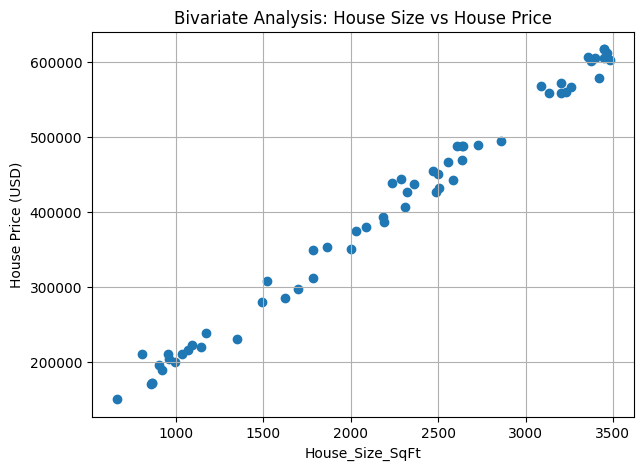


Model Evaluation Results
------------------------
MAE : 11679.78
MSE : 203789709.17
RMSE: 14275.49
R2 Score: 0.9933


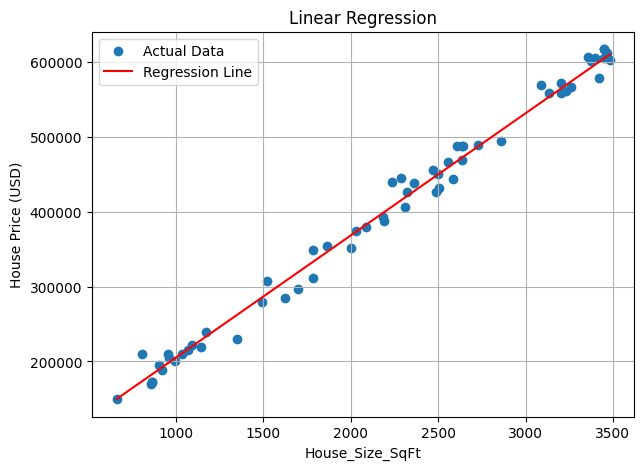


Enter new house House_Size_SqFt: 2000

House Price Prediction
Predicted House Price: $ 368345.76


In [20]:

# Bivariate Analysis and Linear Regression
# House Price Prediction

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error, r2_score

# Step 1: Upload Dataset
print("Upload your House Dataset")
uploaded = files.upload()

file_name = next(iter(uploaded))
data = pd.read_excel(file_name)

print("\nDataset Loaded Successfully!")
print(data.head())

# Step 2: Select Feature
print("\nAvailable Numeric Features:")
print("1. House_Size_SqFt")
print("2. Bedrooms")

feature = input("\nEnter feature name (default: House_Size_SqFt): ").strip()

if feature == "":
    feature = "House_Size_SqFt"

if feature not in ['House_Size_SqFt', 'Bedrooms']:
    raise ValueError("Please enter a valid numeric feature!")

# Step 3: Select X and Y
X = data[[feature]]
y = data['House_Price_USD']

# Step 4: Bivariate Analysis
correlation = data[feature].corr(y)

print("\nBivariate Analysis")
print("Feature:", feature)
print("Target: House_Price_USD")
print("Correlation:", round(correlation, 4))

# Step 5: Display Scatter Plot
plt.figure(figsize=(7, 5))
plt.scatter(X[feature], y)
plt.xlabel(feature)
plt.ylabel("House Price (USD)")
plt.title("Bivariate Analysis: House Size vs House Price")
plt.grid(True)
plt.show()

# Step 6: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Step 7: Train Linear Regression Model
model = LinearRegression()
model.fit(X_train, y_train)

# Step 8: Predict Test Data
y_pred = model.predict(X_test)

# Step 9: Evaluate Model
mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("\nModel Evaluation Results")
print("------------------------")
print("MAE :", round(mae, 2))
print("MSE :", round(mse, 2))
print("RMSE:", round(rmse, 2))
print("R2 Score:", round(r2, 4))

# Step 10: Display Regression Line
plt.figure(figsize=(7, 5))
plt.scatter(X, y, label="Actual Data")

sorted_indices = np.argsort(X[feature].values)
plt.plot(
    X[feature].values[sorted_indices],
    model.predict(X.iloc[sorted_indices]),
    color='red',
    label="Regression Line"
)

plt.xlabel(feature)
plt.ylabel("House Price (USD)")
plt.title("Linear Regression")
plt.legend()
plt.grid(True)
plt.show()

# Step 11: New House Price Prediction
value = float(input("\nEnter new house " + feature + ": "))

new_house = pd.DataFrame([[value]], columns=[feature])
predicted_price = model.predict(new_house)

print("\nHouse Price Prediction")
print("Predicted House Price: $",
      round(predicted_price[0], 2))
